In [12]:
df = pd.read_csv(df)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 57373
Columns: 16


In [13]:
display(df.head())

df.info()

missing_values = df.isna().sum().sort_values(ascending=False)
display(missing_values.to_frame(name="missing_values"))

display(df.describe().T.round(2))

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_name_length,product_description_length,product_photos_qty,product_length_cm,product_height_cm,product_width_cm,product_category_name,product_weight_g,product_match_status
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:00,58.90,13.29,58.0,598.0,4.0,28.0,9.0,14.0,cool_stuff,650.0,Matched
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:00,239.90,19.93,56.0,239.0,2.0,50.0,30.0,40.0,pet_shop,30000.0,Matched
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:00,199.00,17.87,59.0,695.0,2.0,33.0,13.0,33.0,moveis_decoracao,3050.0,Matched
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:00,12.99,12.79,42.0,480.0,1.0,16.0,10.0,15.0,perfumaria,200.0,Matched
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:00,199.90,18.14,59.0,409.0,1.0,35.0,40.0,30.0,ferramentas_jardim,3750.0,Matched


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 57373 entries, 0 to 57372
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   order_id                    57373 non-null  object 
 1   order_item_id               57373 non-null  int64  
 2   product_id                  57373 non-null  object 
 3   seller_id                   57373 non-null  object 
 4   shipping_limit_date         57373 non-null  object 
 5   price                       57373 non-null  float64
 6   freight_value               57373 non-null  float64
 7   product_name_length         56553 non-null  float64
 8   product_description_length  56553 non-null  float64
 9   product_photos_qty          56553 non-null  float64
 10  product_length_cm           56553 non-null  float64
 11  product_height_cm           56553 non-null  float64
 12  product_width_cm            56553 non-null  float64
 13  product_category_name       565

,missing_values
product_name_length,820
product_weight_g,820
product_category_name,820
product_width_cm,820
product_height_cm,820
product_length_cm,820
product_photos_qty,820
product_description_length,820
freight_value,0
price,0


,count,mean,std,min,25%,50%,75%,max
order_item_id,57373.0,1.20,0.73,1.00,1.00,1.00,1.0,21.00
price,57373.0,120.15,180.56,0.85,39.90,74.90,134.9,6735.00
freight_value,57373.0,20.00,15.63,0.00,13.08,16.32,21.2,375.28
product_name_length,56553.0,48.76,10.02,5.00,42.00,52.00,57.0,72.00
product_description_length,56553.0,788.67,654.35,4.00,348.00,603.00,988.0,3985.00
product_photos_qty,56553.0,2.20,1.71,1.00,1.00,1.00,3.0,20.00
product_length_cm,56553.0,30.19,16.16,7.00,18.00,25.00,38.0,105.00
product_height_cm,56553.0,16.60,13.44,2.00,8.00,13.00,20.0,105.00
product_width_cm,56553.0,23.04,11.79,6.00,15.00,20.00,30.0,118.00
product_weight_g,56553.0,2090.86,3737.09,0.00,300.00,700.00,1800.0,40425.00


In [14]:
# 1. Check duplicate records
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate order IDs:", df["order_id"].duplicated().sum())

# 2. Check product matching status
print("\nProduct match status:")
display(df["product_match_status"].value_counts(dropna=False))

# 3. Convert shipping deadline to a proper date format
df["shipping_limit_date"] = pd.to_datetime(
    df["shipping_limit_date"],
    errors="coerce"
)

print("\nInvalid shipping dates:", df["shipping_limit_date"].isna().sum())
print("Earliest shipping deadline:", df["shipping_limit_date"].min())
print("Latest shipping deadline:", df["shipping_limit_date"].max())

# 4. Check category coverage
print("\nUnique product categories:",
      df["product_category_name"].nunique())

print("\nTop 10 categories by record count:")
display(df["product_category_name"].value_counts().head(10))

Duplicate rows: 0
Duplicate order IDs: 0

Product match status:


,count
product_match_status,
Matched,56553
Unmatched,820



Invalid shipping dates: 0
Earliest shipping deadline: 2016-10-08 13:46:00
Latest shipping deadline: 2020-02-05 03:30:00

Unique product categories: 73

Top 10 categories by record count:


,count
product_category_name,
cama_mesa_banho,5662
beleza_saude,4833
esporte_lazer,4322
moveis_decoracao,4280
informatica_acessorios,4018
utilidades_domesticas,3630
relogios_presentes,3121
telefonia,2323
ferramentas_jardim,2254


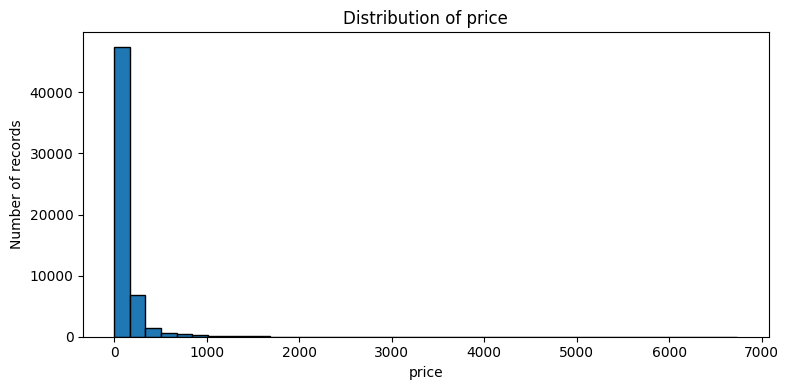

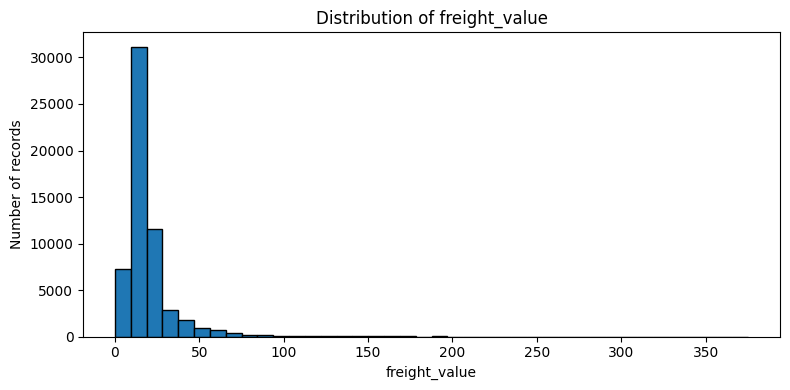

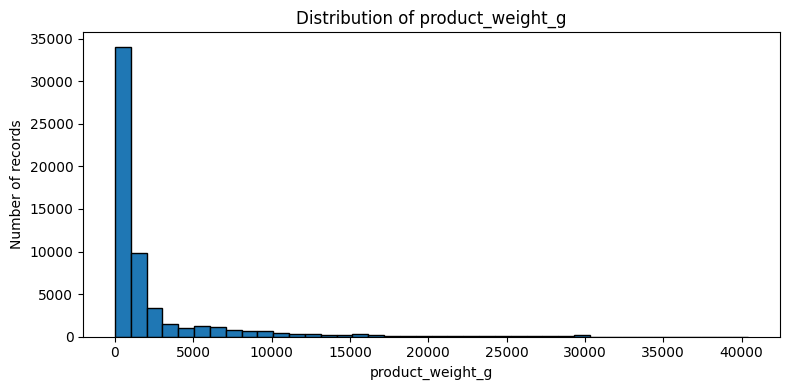

In [15]:
# Plot histograms to understand the distributions
columns = ["price", "freight_value", "product_weight_g"]

for col in columns:
    values = df[col].dropna()

    plt.figure(figsize=(8, 4))
    plt.hist(values, bins=40, edgecolor="black")
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Number of records")
    plt.tight_layout()
    plt.show()

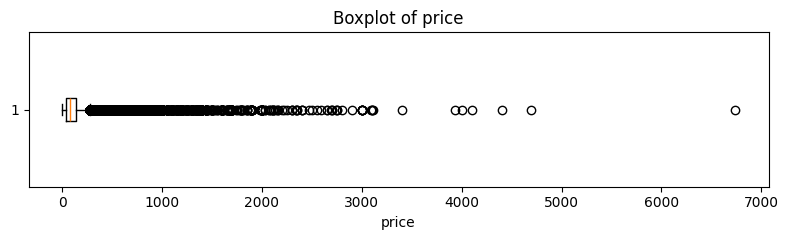

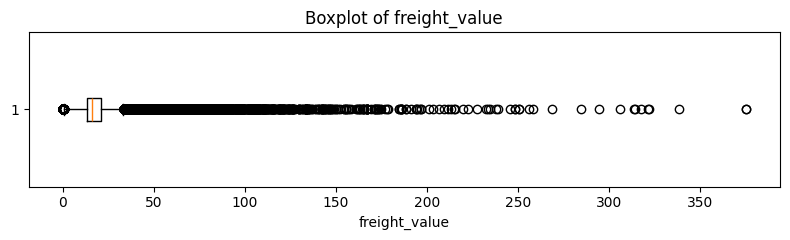

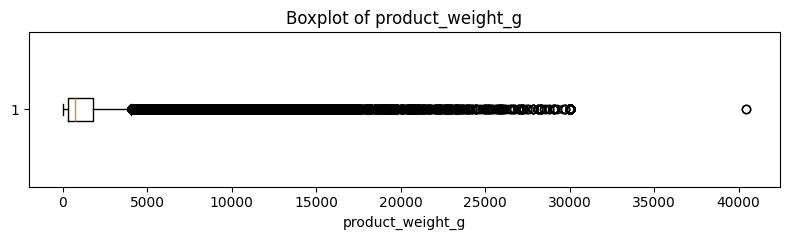

In [16]:
for col in columns:
    values = df[col].dropna()

    plt.figure(figsize=(8, 2.5))
    plt.boxplot(values, vert=False)
    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)
    plt.tight_layout()
    plt.show()

In [17]:
outlier_results = []

for col in columns:
    values = df[col].dropna()

    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = values[
        (values < lower_bound) | (values > upper_bound)
    ]

    outlier_results.append({
        "Column": col,
        "Lower Bound": round(lower_bound, 2),
        "Upper Bound": round(upper_bound, 2),
        "Outlier Count": len(outliers),
        "Outlier Percentage": round(len(outliers) / len(values) * 100, 2)
    })

outlier_summary = pd.DataFrame(outlier_results)
display(outlier_summary)

,Column,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,price,-102.6,277.40,4268,7.44
1,freight_value,0.9,33.38,6183,10.78
2,product_weight_g,-1950.0,4050.00,7921,14.01


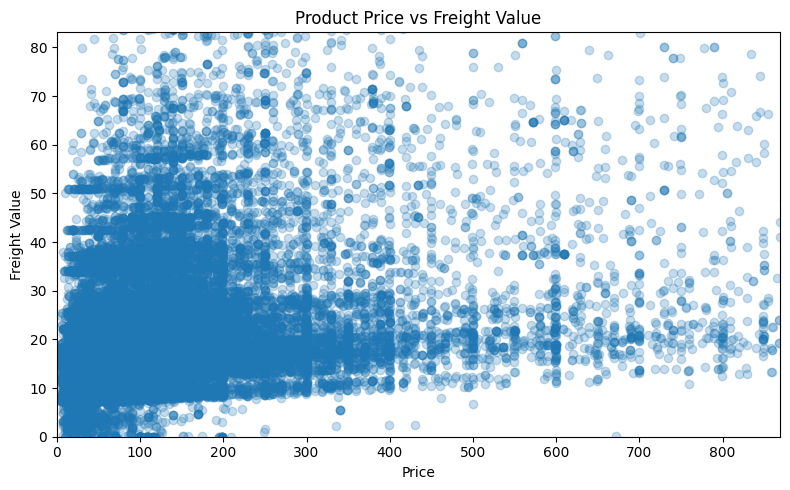

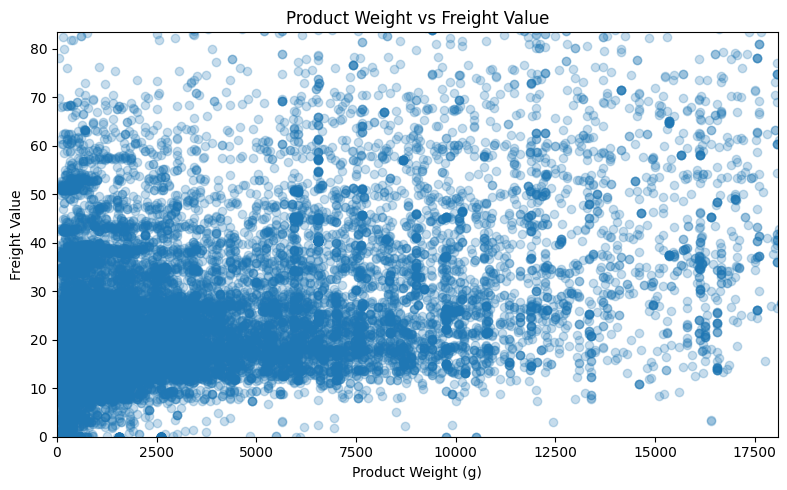

In [18]:
# Relationship between price and freight
plt.figure(figsize=(8, 5))

plt.scatter(df["price"], df["freight_value"], alpha=0.25)

plt.title("Product Price vs Freight Value")
plt.xlabel("Price")
plt.ylabel("Freight Value")

# Zoom in on the central 99% for readability
plt.xlim(0, df["price"].quantile(0.99))
plt.ylim(0, df["freight_value"].quantile(0.99))

plt.tight_layout()
plt.show()


# Relationship between weight and freight
weight_freight = df.dropna(
    subset=["product_weight_g", "freight_value"]
)

plt.figure(figsize=(8, 5))

plt.scatter(
    weight_freight["product_weight_g"],
    weight_freight["freight_value"],
    alpha=0.25
)

plt.title("Product Weight vs Freight Value")
plt.xlabel("Product Weight (g)")
plt.ylabel("Freight Value")

# Zoom in on the central 99% for readability
plt.xlim(0, weight_freight["product_weight_g"].quantile(0.99))
plt.ylim(0, weight_freight["freight_value"].quantile(0.99))

plt.tight_layout()
plt.show()

In [19]:
columns = ["price", "freight_value", "product_weight_g"]

print("Pearson correlation:")
display(df[columns].corr(method="pearson").round(3))

print("Spearman correlation:")
display(df[columns].corr(method="spearman").round(3))

Pearson correlation:


,price,freight_value,product_weight_g
price,1.000,0.407,0.334
freight_value,0.407,1.000,0.612
product_weight_g,0.334,0.612,1.000


Spearman correlation:


,price,freight_value,product_weight_g
price,1.000,0.433,0.518
freight_value,0.433,1.000,0.448
product_weight_g,0.518,0.448,1.000


In [20]:
# Create a category-level performance summary
category_df = df.copy()

category_df["product_category_name"] = (
    category_df["product_category_name"]
    .fillna("unknown_or_unmatched")
)

category_summary = (
    category_df.groupby("product_category_name")
    .agg(
        record_count=("order_id", "count"),
        total_recorded_price=("price", "sum"),
        average_price=("price", "mean"),
        total_freight=("freight_value", "sum"),
        average_freight=("freight_value", "mean")
    )
    .reset_index()
)

# Freight as a percentage of recorded price
category_summary["freight_pct_of_recorded_price"] = (
    category_summary["total_freight"]
    / category_summary["total_recorded_price"]
    * 100
)

category_summary = category_summary.sort_values(
    "total_recorded_price", ascending=False
)

display(category_summary.head(10).round(2))

,product_category_name,record_count,total_recorded_price,average_price,total_freight,average_freight,freight_pct_of_recorded_price
66,relogios_presentes,3121,624736.04,200.17,51823.87,16.60,8.30
11,beleza_saude,4833,617886.99,127.85,91370.10,18.91,14.79
13,cama_mesa_banho,5662,526535.28,92.99,104017.91,18.37,19.76
32,esporte_lazer,4322,483328.94,111.83,83923.09,19.42,17.36
44,informatica_acessorios,4018,460959.49,114.72,75648.17,18.83,16.41
54,moveis_decoracao,4280,379708.71,88.72,89440.35,20.90,23.55
73,utilidades_domesticas,3630,329203.04,90.69,75581.55,20.82,22.96
26,cool_stuff,1917,309179.46,161.28,41473.89,21.63,13.41
8,automotivo,2081,289110.46,138.93,45841.21,22.03,15.86
40,ferramentas_jardim,2254,258854.26,114.84,52040.27,23.09,20.10


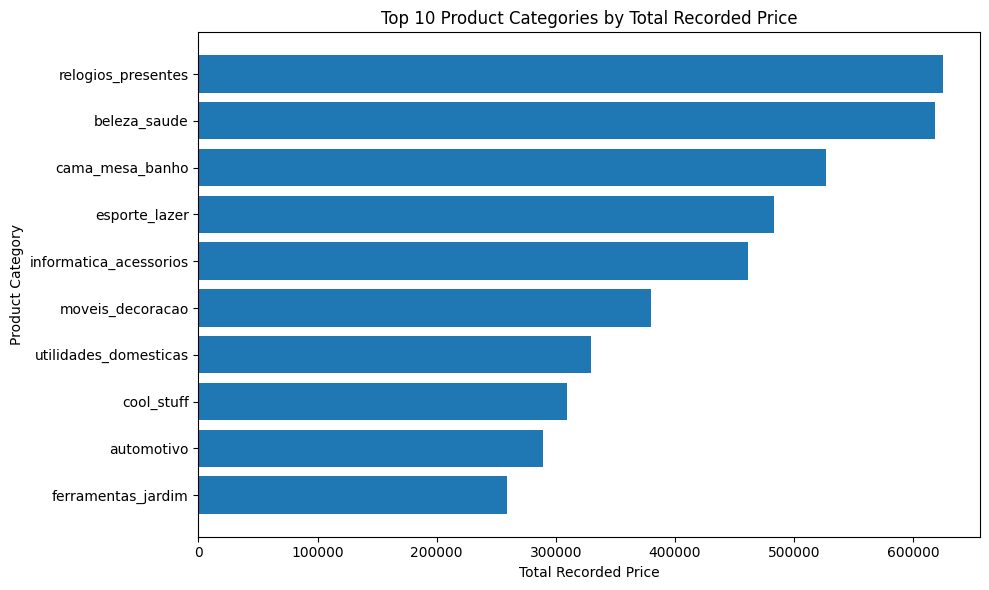

In [21]:
top_categories = category_summary.head(10).sort_values(
    "total_recorded_price"
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_categories["product_category_name"],
    top_categories["total_recorded_price"]
)

plt.title("Top 10 Product Categories by Total Recorded Price")
plt.xlabel("Total Recorded Price")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

In [22]:
product_summary = (
    df.dropna(subset=["product_id"])
    .groupby("product_id")
    .agg(
        product_category=("product_category_name", "first"),
        record_count=("order_id", "count"),
        total_recorded_price=("price", "sum"),
        average_price=("price", "mean"),
        total_freight=("freight_value", "sum")
    )
    .reset_index()
    .sort_values("total_recorded_price", ascending=False)
)

display(product_summary.head(10).round(2))

,product_id,product_category,record_count,total_recorded_price,average_price,total_freight
15733,bb50f2e236e5eea0100680137654686c,beleza_saude,91,29800.00,327.47,1681.13
17705,d1c427060a0f73f6b889a5c7c61f2ac4,informatica_acessorios,183,25255.21,138.01,7638.18
9181,6cdd53843498f92890544667809f1595,beleza_saude,71,24952.60,351.45,1964.17
18084,d6160fb7873f184099d9bc95e30376af,pcs,18,24599.83,1366.66,717.50
12905,99a4788cb24856965c36a24e339b6058,cama_mesa_banho,239,20993.79,87.84,3963.64
5283,3dd2a17168ec895c781a9191c1e95ad7,informatica_acessorios,136,20386.40,149.90,3463.27
14447,aca2eb7d00ea1a7b8ebd4e68314663af,moveis_decoracao,282,20119.00,71.34,3721.63
7541,588531f8ec37e7d5ff5b7b22ea0488f8,pcs,14,19644.00,1403.14,555.06
3256,25c38557cf793876c5abdd5931f922db,bebes,17,17526.56,1030.97,646.61
7134,53b36df67ebb7c41585e8d54d6772e08,relogios_presentes,150,17434.76,116.23,1005.05


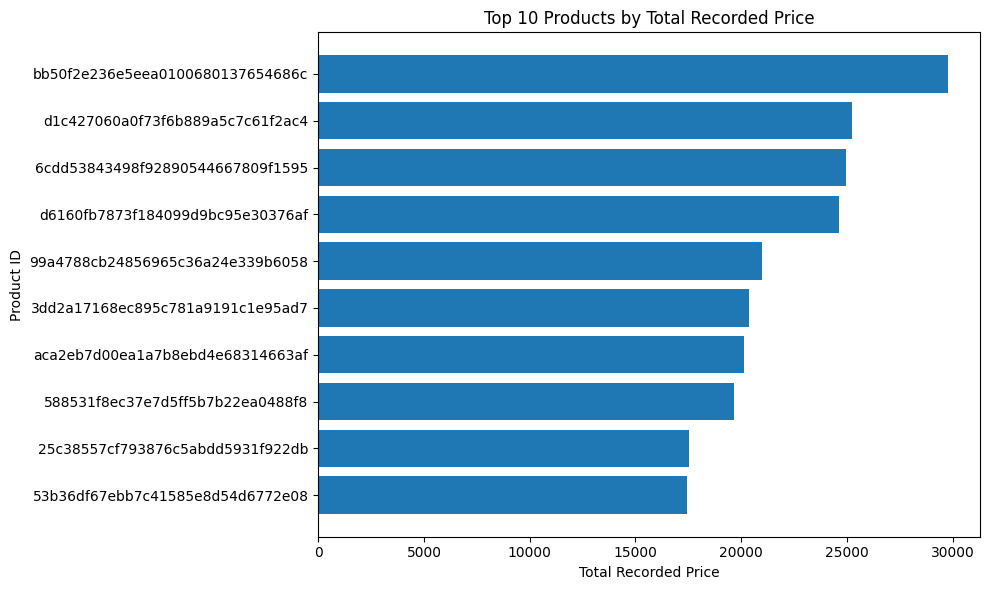

In [23]:
top_products = product_summary.head(10).sort_values(
    "total_recorded_price"
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_products["product_id"].astype(str),
    top_products["total_recorded_price"]
)

plt.title("Top 10 Products by Total Recorded Price")
plt.xlabel("Total Recorded Price")
plt.ylabel("Product ID")
plt.tight_layout()
plt.show()

In [24]:
# Rank products from highest to lowest recorded price
product_pareto = product_summary.sort_values(
    "total_recorded_price",
    ascending=False
).copy()

# Calculate each product's contribution
grand_total = product_pareto["total_recorded_price"].sum()

product_pareto["contribution_pct"] = (
    product_pareto["total_recorded_price"] / grand_total * 100
)

# Calculate cumulative contribution
product_pareto["cumulative_pct"] = (
    product_pareto["contribution_pct"].cumsum()
)

product_pareto["product_rank"] = range(
    1, len(product_pareto) + 1
)

# Find how many top products are needed to reach 80%
products_for_80 = (
    product_pareto["cumulative_pct"].lt(80).sum() + 1
)

top_10_share = product_pareto.head(10)["contribution_pct"].sum()

print("Total recorded price:", round(grand_total, 2))
print("Top 10 products' contribution:", round(top_10_share, 2), "%")
print("Products needed to reach at least 80%:",
      products_for_80)

display(
    product_pareto.head(10)[
        [
            "product_id",
            "total_recorded_price",
            "contribution_pct",
            "cumulative_pct"
        ]
    ].round(2)
)

Total recorded price: 6893558.78
Top 10 products' contribution: 3.2 %
Products needed to reach at least 80%: 6428


,product_id,total_recorded_price,contribution_pct,cumulative_pct
15733,bb50f2e236e5eea0100680137654686c,29800.00,0.43,0.43
17705,d1c427060a0f73f6b889a5c7c61f2ac4,25255.21,0.37,0.80
9181,6cdd53843498f92890544667809f1595,24952.60,0.36,1.16
18084,d6160fb7873f184099d9bc95e30376af,24599.83,0.36,1.52
12905,99a4788cb24856965c36a24e339b6058,20993.79,0.30,1.82
5283,3dd2a17168ec895c781a9191c1e95ad7,20386.40,0.30,2.12
14447,aca2eb7d00ea1a7b8ebd4e68314663af,20119.00,0.29,2.41
7541,588531f8ec37e7d5ff5b7b22ea0488f8,19644.00,0.28,2.69
3256,25c38557cf793876c5abdd5931f922db,17526.56,0.25,2.95
7134,53b36df67ebb7c41585e8d54d6772e08,17434.76,0.25,3.20


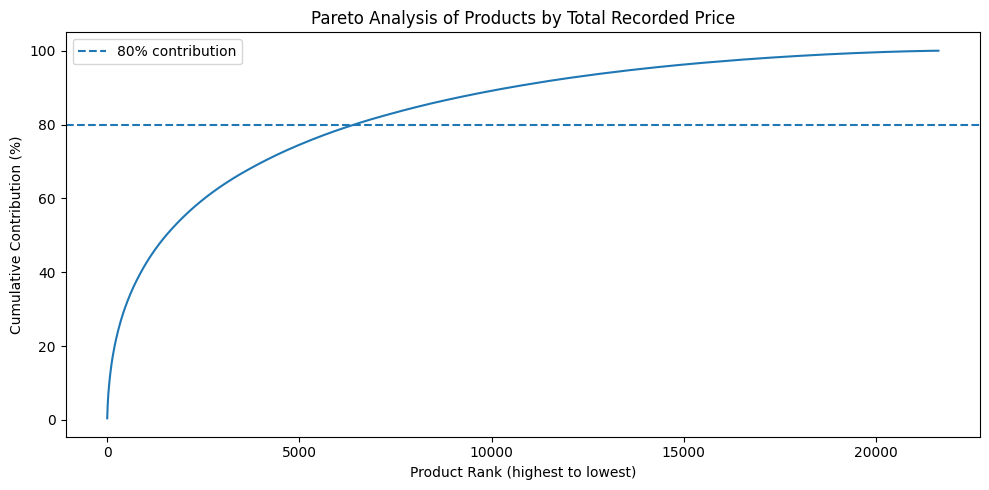

In [25]:
plt.figure(figsize=(10, 5))

plt.plot(
    product_pareto["product_rank"],
    product_pareto["cumulative_pct"]
)

plt.axhline(
    y=80,
    linestyle="--",
    label="80% contribution"
)

plt.xlabel("Product Rank (highest to lowest)")
plt.ylabel("Cumulative Contribution (%)")
plt.title("Pareto Analysis of Products by Total Recorded Price")
plt.legend()
plt.tight_layout()
plt.show()

In [26]:
pcs_rows = df[
    df["product_category_name"]
    .astype("string")
    .str.strip()
    .str.lower()
    .eq("pcs")
]

print("Records with category 'pcs':", len(pcs_rows))

display(
    pcs_rows[
        [
            "product_id",
            "product_category_name",
            "price",
            "freight_value",
            "product_match_status"
        ]
    ].head(10)
)

Records with category 'pcs': 113


,product_id,product_category_name,price,freight_value,product_match_status
1643,a04087ab6a96ffa041f8a2701a72b616,pcs,599.00,73.41,Matched
2010,a04087ab6a96ffa041f8a2701a72b616,pcs,599.00,58.63,Matched
2604,bc4cd4da98dd128c39bf0b8c2674032f,pcs,1200.00,20.00,Matched
3894,588531f8ec37e7d5ff5b7b22ea0488f8,pcs,1437.00,34.51,Matched
3895,d6160fb7873f184099d9bc95e30376af,pcs,1300.00,28.59,Matched
4133,588531f8ec37e7d5ff5b7b22ea0488f8,pcs,1200.00,60.76,Matched
4419,e004a3b7f9524967fdb68bb70f850eb0,pcs,730.00,80.13,Matched
4477,d6160fb7873f184099d9bc95e30376af,pcs,1300.00,33.55,Matched
4850,34f99d82cfc355d08d8db780d14aa002,pcs,2999.99,126.51,Matched
4854,588531f8ec37e7d5ff5b7b22ea0488f8,pcs,1200.00,40.85,Matched


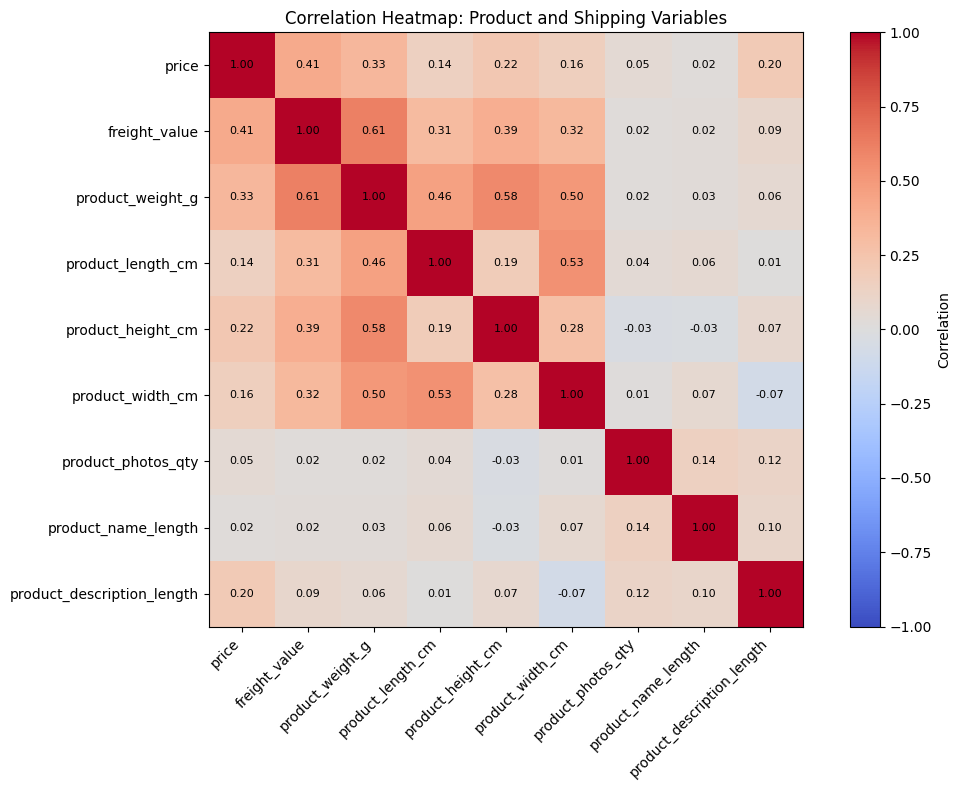

In [27]:
# Select numeric product and shipping variables
numeric_cols = [
    "price",
    "freight_value",
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm",
    "product_photos_qty",
    "product_name_length",
    "product_description_length"
]

corr_matrix = df[numeric_cols].corr()

# Plot correlation heatmap
fig, ax = plt.subplots(figsize=(11, 8))

im = ax.imshow(corr_matrix, vmin=-1, vmax=1, cmap="coolwarm")

ax.set_xticks(range(len(numeric_cols)))
ax.set_yticks(range(len(numeric_cols)))

ax.set_xticklabels(numeric_cols, rotation=45, ha="right")
ax.set_yticklabels(numeric_cols)

# Display correlation values in each cell
for i in range(len(numeric_cols)):
    for j in range(len(numeric_cols)):
        ax.text(
            j, i,
            f"{corr_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=8
        )

plt.colorbar(im, ax=ax, label="Correlation")
plt.title("Correlation Heatmap: Product and Shipping Variables")
plt.tight_layout()
plt.show()

In [28]:
from pathlib import Path

output_dir = Path("/content/eda_outputs")
output_dir.mkdir(exist_ok=True)

category_summary.to_csv(
    output_dir / "category_summary.csv", index=False
)

product_summary.to_csv(
    output_dir / "product_summary.csv", index=False
)

product_pareto.to_csv(
    output_dir / "product_pareto.csv", index=False
)

print("Saved files:")
for file in output_dir.iterdir():
    print(file.name)

Saved files:
product_summary.csv
category_summary.csv
product_pareto.csv
